<a href="https://colab.research.google.com/github/aliosnamoor2-dot/LIAD7002-actividad1/blob/main/LIADAct002.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q pyspark

PySpark

In [ ]:
import time
import logging
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import auth, userdata
from google.cloud import bigquery

logging.basicConfig(level=logging.INFO, format="%(asctime)s | %(levelname)s | %(message)s")

# --- Parámetros del proyecto ---
PROJECT_ID = "economia-mx"
DATASET_ID = "economia_mx"
ANIO_INI, ANIO_FIN = 2000, 2025
SERIE_TC = "SF43718"              # Tipo de cambio FIX USD/MXN - diario
SERIE_INPC = "SP74665"            # INPC general - mensual

BANXICO_URL = "https://www.banxico.org.mx/SieAPIRest/service/v1/series"
WB_URL = "https://api.worldbank.org/v2/country/MX/indicator"
WB_INDICADORES = {
    "pib_crec": "NY.GDP.MKTP.KD.ZG",    # Crecimiento del PIB - % anual
    "inflacion_wb": "FP.CPI.TOTL.ZG",   # Inflación, precios al consumidor - % anual
    "gini": "SI.POV.GINI",              # Índice de Gini
}

TBL_TC = f"{PROJECT_ID}.{DATASET_ID}.tc_mensual"
TBL_ETL = f"{PROJECT_ID}.{DATASET_ID}.etl_macro_anual"

try:
    BANXICO_TOKEN = userdata.get("BANXICO_TOKEN")
except Exception as e:
    raise RuntimeError("Falta el secreto BANXICO_TOKEN en Colab (ícono de la llave) o no tiene acceso activado.") from e
print("Configuración lista.")

Configuración lista.


Imports y parámetros

In [ ]:
def _get_json(url, headers=None, params=None, intentos=3):

    for i in range(1, intentos + 1):
        try:
            r = requests.get(url, headers=headers, params=params, timeout=30)
            r.raise_for_status()
            return r.json()
        except requests.exceptions.HTTPError as e:
            if e.response is not None and e.response.status_code < 500:
                raise
            if i == intentos:
                raise
            logging.warning(f"Error de servidor, reintento {i}/{intentos - 1}")
            time.sleep(2 * i)
        except (requests.exceptions.ConnectionError, requests.exceptions.Timeout):
            if i == intentos:
                raise
            logging.warning(f"Problema de conexión, reintento {i}/{intentos - 1}")
            time.sleep(2 * i)


def extraer_banxico(serie_id, anio_ini, anio_fin, token, paso=3):
    """Descarga una serie del SIE de Banxico por bloques de `paso` años. Regresa DataFrame [fecha, valor]."""
    headers = {"Bmx-Token": token, "Accept": "application/json"}
    filas = []
    for y in range(anio_ini, anio_fin + 1, paso):
        ini, fin = f"{y}-01-01", f"{min(y + paso - 1, anio_fin)}-12-31"
        js = _get_json(f"{BANXICO_URL}/{serie_id}/datos/{ini}/{fin}", headers=headers)
        for s in js["bmx"]["series"]:
            for d in s.get("datos", []):
                filas.append({"fecha": d["fecha"], "valor": d["dato"]})
    if not filas:
        raise ValueError(f"Banxico no regresa datos para la serie {serie_id}")
    df = pd.DataFrame(filas)
    df["fecha"] = pd.to_datetime(df["fecha"], format="%d/%m/%Y")
    df["valor"] = pd.to_numeric(df["valor"].str.replace(",", ""), errors="coerce")  # "N/E" -> NaN
    return df.dropna(subset=["valor"]).sort_values("fecha").reset_index(drop=True)


def extraer_worldbank(indicador, anio_ini, anio_fin):
    """Descarga un indicador del World Bank para México. Regresa DataFrame [anio, valor]."""
    params = {"format": "json", "per_page": 100, "date": f"{anio_ini}:{anio_fin}"}
    payload = _get_json(f"{WB_URL}/{indicador}", params=params)
    if not isinstance(payload, list) or len(payload) < 2 or not payload[1]:
        raise ValueError(f"World Bank no regresó datos para {indicador}: {str(payload)[:200]}")
    _meta, datos = payload
    df = pd.DataFrame(datos)[["date", "value"]].rename(columns={"date": "anio", "value": "valor"})
    df["anio"] = df["anio"].astype(int)
    return df.sort_values("anio").reset_index(drop=True)

print("Funciones de extracción definidas.")


Funciones de extracción definidas.


[texto del enlace](https://)Funciones de extracción

In [ ]:
def _get_json(url, headers=None, params=None, intentos=3):
    for i in range(1, intentos + 1):
        try:
            r = requests.get(url, headers=headers, params=params, timeout=30)
            r.raise_for_status()
            return r.json()
        except requests.exceptions.HTTPError as e:
            if e.response is not None and e.response.status_code < 500:
                raise
            if i == intentos:
                raise
            logging.warning(f"Error de servidor, reintento {i}/{intentos - 1}")
            time.sleep(2 * i)
        except (requests.exceptions.ConnectionError, requests.exceptions.Timeout):
            if i == intentos:
                raise
            logging.warning(f"Problema de conexión, reintento {i}/{intentos - 1}")
            time.sleep(2 * i)


def extraer_banxico(serie_id, anio_ini, anio_fin, token, paso=3):
    headers = {"Bmx-Token": token, "Accept": "application/json"}
    filas = []
    for y in range(anio_ini, anio_fin + 1, paso):
        ini, fin = f"{y}-01-01", f"{min(y + paso - 1, anio_fin)}-12-31"
        js = _get_json(f"{BANXICO_URL}/{serie_id}/datos/{ini}/{fin}", headers=headers)
        for s in js["bmx"]["series"]:
            for d in s.get("datos", []):
                filas.append({"fecha": d["fecha"], "valor": d["dato"]})
    if not filas:
        raise ValueError(f"Banxico no regresó datos para la serie {serie_id}")
    df = pd.DataFrame(filas)
    df["fecha"] = pd.to_datetime(df["fecha"], format="%d/%m/%Y")
    df["valor"] = pd.to_numeric(df["valor"].str.replace(",", ""), errors="coerce")  # "N/E" -> NaN
    return df.dropna(subset=["valor"]).sort_values("fecha").reset_index(drop=True)


def extraer_worldbank(indicador, anio_ini, anio_fin):
    params = {"format": "json", "per_page": 100, "date": f"{anio_ini}:{anio_fin}"}
    payload = _get_json(f"{WB_URL}/{indicador}", params=params)
    if not isinstance(payload, list) or len(payload) < 2 or not payload[1]:
        raise ValueError(f"World Bank no regresó datos para {indicador}: {str(payload)[:200]}")
    _meta, datos = payload
    df = pd.DataFrame(datos)[["date", "value"]].rename(columns={"date": "anio", "value": "valor"})
    df["anio"] = df["anio"].astype(int)
    return df.sort_values("anio").reset_index(drop=True)

print("Funciones de extracción definidas.")

Funciones de extracción definidas.


Tipo de cambio

In [ ]:
df_tc = extraer_banxico(SERIE_TC, ANIO_INI, ANIO_FIN, BANXICO_TOKEN)
print(f"Filas reales descargadas: {len(df_tc):,}")
assert len(df_tc) >= 500,  "No hay suficientes datos para el análisis"
df_tc.head()

Filas reales descargadas: 6,544


,fecha,valor
0,2000-01-03,9.3949
1,2000-01-04,9.4564
2,2000-01-05,9.5455
3,2000-01-06,9.5705
4,2000-01-07,9.5150


Pasar a Spark DataFrame

In [ ]:
from pyspark.sql import SparkSession, functions as F

spark = (SparkSession.builder
         .master("local[*]")
         .appName("Actividad2_TipoDeCambio")
         .getOrCreate())

sdf = spark.createDataFrame(df_tc.rename(columns={"valor": "tc"}))
sdf.printSchema()
print("Filas en el Spark DataFrame:", sdf.count())
sdf.show(5)

root
 |-- fecha: timestamp (nullable = true)
 |-- tc: double (nullable = true)

Filas en el Spark DataFrame: 6544
+-------------------+------+
|              fecha|    tc|
+-------------------+------+
|2000-01-03 00:00:00|9.3949|
|2000-01-04 00:00:00|9.4564|
|2000-01-05 00:00:00|9.5455|
|2000-01-06 00:00:00|9.5705|
|2000-01-07 00:00:00| 9.515|
+-------------------+------+
only showing top 5 rows


Transformaciones en Spark

In [ ]:
def procesar_spark(sdf):
    return (sdf
            .filter(F.col("tc").isNotNull() & (F.col("tc") > 0))              # 1) filter
            .withColumn("anio", F.year("fecha"))
            .withColumn("mes", F.month("fecha"))
            .groupBy("anio", "mes")                                           # 2) groupBy + agg
            .agg(F.round(F.avg("tc"), 4).alias("tc_promedio"),
                 F.round(F.min("tc"), 4).alias("tc_min"),
                 F.round(F.max("tc"), 4).alias("tc_max"),
                 F.round(F.stddev("tc"), 4).alias("tc_desv"),
                 F.count("*").alias("n_dias"))
            .withColumn("rango_pct", F.round((F.col("tc_max") - F.col("tc_min")) / F.col("tc_promedio") * 100, 3))
            .orderBy("anio", "mes"))                                          # 3) orderBy

res_spark = procesar_spark(sdf)
print("Filas del resultado (año-mes):", res_spark.count())
res_spark.show(12)

Filas del resultado (año-mes): 312
+----+---+-----------+------+-------+-------+------+---------+
|anio|mes|tc_promedio|tc_min| tc_max|tc_desv|n_dias|rango_pct|
+----+---+-----------+------+-------+-------+------+---------+
|2000|  1|     9.4878|9.3949| 9.6253| 0.0624|    21|    2.428|
|2000|  2|     9.4252|9.3592| 9.5956| 0.0635|    21|    2.508|
|2000|  3|     9.2876|9.1712| 9.3633| 0.0543|    22|    2.068|
|2000|  4|     9.3903|9.2761| 9.4882| 0.0637|    18|    2.259|
|2000|  5|     9.5158|9.3374|  9.615| 0.0702|    21|    2.917|
|2000|  6|     9.8295|9.4988|10.0787| 0.1509|    22|      5.9|
|2000|  7|     9.4212|9.3327| 9.5461|  0.076|    21|    2.265|
|2000|  8|     9.2709|9.1873| 9.3881| 0.0607|    23|    2.166|
|2000|  9|      9.354|9.2014|  9.479| 0.0834|    21|    2.968|
|2000| 10|     9.5314|9.4014| 9.6777| 0.0761|    22|    2.899|
|2000| 11|     9.5004|9.3692| 9.6544| 0.1027|    20|    3.002|
|2000| 12|     9.4662|9.3737| 9.6098| 0.0862|    18|    2.494|
+----+---+----------

Tiempos pandas vs. PySpark

In [ ]:
def procesar_pandas(df):
    d = df[df["valor"] > 0].copy()
    d["anio"], d["mes"] = d["fecha"].dt.year, d["fecha"].dt.month
    g = (d.groupby(["anio", "mes"])["valor"]
           .agg(tc_promedio="mean", tc_min="min", tc_max="max", tc_desv="std", n_dias="count")
           .reset_index().sort_values(["anio", "mes"]))
    return g

def medir(fn, repeticiones=5):
    tiempos = []
    for _ in range(repeticiones):
        t0 = time.perf_counter()
        fn()
        tiempos.append(time.perf_counter() - t0)
    return tiempos

t_pandas = medir(lambda: procesar_pandas(df_tc))
t_spark = medir(lambda: procesar_spark(sdf).collect())

comparacion = pd.DataFrame({
    "motor": ["pandas", "PySpark"],
    "primera_ejecucion_s": [t_pandas[0], t_spark[0]],
    "mediana_5_ejecuciones_s": [float(np.median(t_pandas)), float(np.median(t_spark))],
}).round(4)
comparacion

,motor,primera_ejecucion_s,mediana_5_ejecuciones_s
0,pandas,0.0459,0.0459
1,PySpark,1.4026,1.8986


Gráfica de la comparación

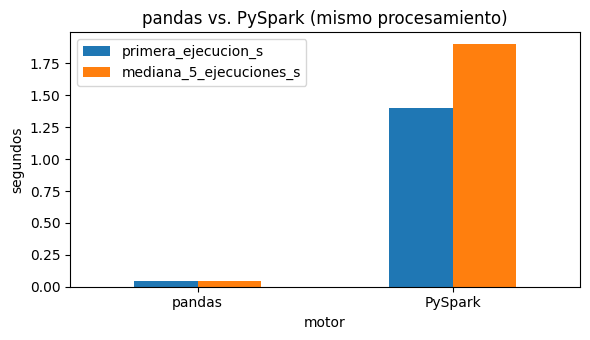

In [ ]:
ax = comparacion.set_index("motor")[["primera_ejecucion_s", "mediana_5_ejecuciones_s"]].plot(kind="bar", rot=0, figsize=(6, 3.5))
ax.set_ylabel("segundos"); ax.set_title("pandas vs. PySpark (mismo procesamiento)")
plt.tight_layout(); plt.show()

Conexión

In [ ]:
auth.authenticate_user()
client = bigquery.Client(project=PROJECT_ID)

dataset = bigquery.Dataset(f"{PROJECT_ID}.{DATASET_ID}")
dataset.location = "US"
client.create_dataset(dataset, exists_ok=True)

print("Proyecto:", client.project)
print("Datasets:", [d.dataset_id for d in client.list_datasets()])

Proyecto: economia-mx
Datasets: ['economia_mx']


Cargar el resultado de Spark como tabla

In [ ]:
def cargar_a_bigquery(df, tabla_completa):
    cfg = bigquery.LoadJobConfig(write_disposition="WRITE_TRUNCATE")
    client.load_table_from_dataframe(df, tabla_completa, job_config=cfg).result()
    t = client.get_table(tabla_completa)
    print(f"Tabla cargada: {t.full_table_id} | filas: {t.num_rows:,} | columnas: {len(t.schema)}")
    return t

df_tc_mensual = res_spark.toPandas()
tabla_tc = cargar_a_bigquery(df_tc_mensual, TBL_TC)

Tabla cargada: economia-mx:economia_mx.tc_mensual | filas: 312 | columnas: 8


Consulta 1, promedio anual y variación

In [ ]:
def q(sql):
    return client.query(sql).to_dataframe()

sql1 = f"""
SELECT anio,
       ROUND(AVG(tc_promedio), 4) AS tc_prom_anual,
       ROUND(MIN(tc_min), 4) AS tc_min,
       ROUND(MAX(tc_max), 4) AS tc_max,
       ROUND(100 * (AVG(tc_promedio) / LAG(AVG(tc_promedio)) OVER (ORDER BY anio) - 1), 2) AS var_pct_vs_anio_ant
FROM `{TBL_TC}`
GROUP BY anio
ORDER BY anio
"""
q1 = q(sql1)
q1

,anio,tc_prom_anual,tc_min,tc_max,var_pct_vs_anio_ant
0,2000,9.4567,9.1712,10.0787,NaN
1,2001,9.3390,8.9428,9.9778,-1.24
2,2002,9.6657,8.9980,10.4393,3.50
3,2003,10.7953,10.1068,11.3985,11.69
4,2004,11.2859,10.8172,11.6328,4.54
5,2005,10.8939,10.4097,11.4018,-3.47
6,2006,10.9007,10.4303,11.4809,0.06
7,2007,10.9288,10.6639,11.2676,0.26
8,2008,11.1520,9.9180,13.9183,2.04
9,2009,13.5076,12.5969,15.3650,21.12


Consulta 2, los 10 meses más volátiles

In [ ]:
sql2 = f"""
SELECT anio, mes, tc_promedio, tc_min, tc_max, rango_pct
FROM `{TBL_TC}`
ORDER BY rango_pct DESC
LIMIT 10
"""
q2 = q(sql2)
q2

,anio,mes,tc_promedio,tc_min,tc_max,rango_pct
0,2020,3,22.3784,19.2837,25.1185,26.073
1,2008,10,12.6314,10.9811,13.5592,20.410
2,2016,11,20.1185,18.5089,21.0511,12.636
3,2011,9,13.0445,12.2616,13.8917,12.496
4,2008,11,13.1140,12.4862,13.9183,10.920
5,2012,5,13.6634,12.9629,14.3047,9.820
6,2020,5,23.4230,22.1778,24.3812,9.407
7,2009,3,14.6695,14.0502,15.3650,8.963
8,2018,10,19.1859,18.6531,20.3177,8.676
9,2018,7,19.0095,18.5413,20.1453,8.438


Consulta 3, comparación por quinquenio

In [ ]:
sql3 = f"""
SELECT CONCAT(CAST(DIV(anio, 5) * 5 AS STRING), '-', CAST(DIV(anio, 5) * 5 + 4 AS STRING)) AS quinquenio,
       ROUND(AVG(tc_promedio), 2) AS tc_promedio,
       ROUND(AVG(tc_desv), 3) AS volatilidad_promedio,
       SUM(n_dias) AS dias_observados
FROM `{TBL_TC}`
GROUP BY quinquenio
ORDER BY quinquenio
"""
q3 = q(sql3)
q3

,quinquenio,tc_promedio,volatilidad_promedio,dias_observados
0,2000-2004,10.11,0.083,1261
1,2005-2009,11.48,0.121,1259
2,2010-2014,12.86,0.138,1258
3,2015-2019,18.40,0.244,1256
4,2020-2024,19.59,0.267,1259
5,2025-2029,19.22,0.154,251


Pipeline ETL

In [ ]:
def transformar(df_tc_diario, df_inpc, dfs_wb, anio_ini, anio_fin):
    # 1) Tipo de cambio diario -> anual
    tc = df_tc_diario.copy()
    tc["anio"] = tc["fecha"].dt.year
    tc_anual = (tc.groupby("anio")
                  .agg(tc_promedio=("valor", "mean"), tc_cierre=("valor", "last"))
                  .reset_index())
    tc_anual["tc_var_pct"] = tc_anual["tc_promedio"].pct_change() * 100   # depreciación (+) / apreciación (-)

    # 2) INPC mensual -> inflación anual (dic/dic)
    inpc = df_inpc.set_index("fecha")["valor"].asfreq("MS")      # índice mensual completo
    infl_yoy = (inpc.pct_change(12) * 100).dropna().reset_index(name="infl")
    infl_dic = infl_yoy[infl_yoy["fecha"].dt.month == 12].copy()
    infl_dic["anio"] = infl_dic["fecha"].dt.year
    infl_dic = infl_dic[["anio", "infl"]].rename(columns={"infl": "inflacion_banxico"})

    # 3) World Bank (ya es anual)
    out = tc_anual.merge(infl_dic, on="anio", how="left")
    for nombre, dfw in dfs_wb.items():
        out = out.merge(dfw.rename(columns={"valor": nombre}), on="anio", how="left")

    out = out[(out["anio"] >= anio_ini) & (out["anio"] <= anio_fin)].copy()
    out["dif_inflacion"] = out["inflacion_banxico"] - out["inflacion_wb"]
    assert out["anio"].is_unique, "Hay años duplicados después del merge"
    return out.round(4).sort_values("anio").reset_index(drop=True)


def pipeline_etl(anio_ini=ANIO_INI, anio_fin=ANIO_FIN, token=BANXICO_TOKEN,
                 tabla_destino=TBL_ETL, cargar_bq=True, df_tc_diario=None):
    try:
        logging.info("EXTRACT: Banxico y World Bank")
        if df_tc_diario is None:
            df_tc_diario = extraer_banxico(SERIE_TC, anio_ini, anio_fin, token)
        df_inpc = extraer_banxico(SERIE_INPC, anio_ini - 1, anio_fin, token)
        dfs_wb = {nombre: extraer_worldbank(ind, anio_ini, anio_fin) for nombre, ind in WB_INDICADORES.items()}

        logging.info("TRANSFORM: normalización anual y merge")
        df_final = transformar(df_tc_diario, df_inpc, dfs_wb, anio_ini, anio_fin)
        logging.info(f"Filas resultantes: {len(df_final)} | nulos por columna: {df_final.isna().sum().to_dict()}")

        if cargar_bq:
            logging.info("LOAD: BigQuery")
            cargar_a_bigquery(df_final, tabla_destino)
        return df_final

    except requests.exceptions.HTTPError as e:
        codigo = e.response.status_code if e.response is not None else "?"
        logging.error(f"Error HTTP {codigo}. Revisa el token, el ID de la serie o la URL. Detalle: {e}")
    except requests.exceptions.RequestException as e:
        logging.error(f"Error de red al consumir una API: {e}")
    except (KeyError, ValueError) as e:
        logging.error(f"La respuesta de una API no tiene el formato esperado: {e}")
    except Exception as e:
        logging.error(f"Error inesperado en el pipeline: {type(e).__name__}: {e}")
    return None

Ejecutar el pipeline

In [ ]:
df_etl = pipeline_etl(df_tc_diario=df_tc)
df_etl

Tabla cargada: economia-mx:economia_mx.etl_macro_anual | filas: 26 | columnas: 9


,anio,tc_promedio,tc_cierre,tc_var_pct,inflacion_banxico,pib_crec,inflacion_wb,gini,dif_inflacion
0,2000,9.4568,9.6098,NaN,81.9133,5.0293,9.4916,53.4,72.4217
1,2001,9.3360,9.1695,-1.2777,-85.6204,-0.4508,6.3677,NaN,-91.9881
2,2002,9.6714,10.4393,3.5926,547.4286,-0.2366,5.0307,50.6,542.3978
3,2003,10.7913,11.2372,11.5799,-61.4298,1.1855,4.5469,NaN,-65.9767
4,2004,11.2871,11.1495,4.5936,121.2815,3.5654,4.6884,50.3,116.5931
5,2005,10.8895,10.6344,-3.5222,-63.4953,2.1132,3.9881,50.9,-67.4834
6,2006,10.9034,10.8116,0.1274,53.5411,4.8050,3.6295,49.7,49.9116
7,2007,10.9274,10.9157,0.2207,-37.4539,2.0779,3.9668,NaN,-41.4207
8,2008,11.1438,13.8325,1.9801,189.0855,0.9433,5.1250,50.8,183.9606
9,2009,13.4983,13.0659,21.1283,-82.4490,-6.2953,5.2974,NaN,-87.7463


Prueba del manejo de errores

In [ ]:
resultado_prueba = pipeline_etl(token="TOKEN_INVALIDO", cargar_bq=False) # Prueba: token inválido, debe registrar el error y devolver None
print("Resultado con token inválido:", resultado_prueba)

ERROR:root:Error HTTP 400. Revisa el token, el ID de la serie o la URL. Detalle: 400 Client Error: Bad Request for url: https://www.banxico.org.mx/SieAPIRest/service/v1/series/SF43718/datos/2000-01-01/2002-12-31


Resultado con token inválido: None


Gráfica

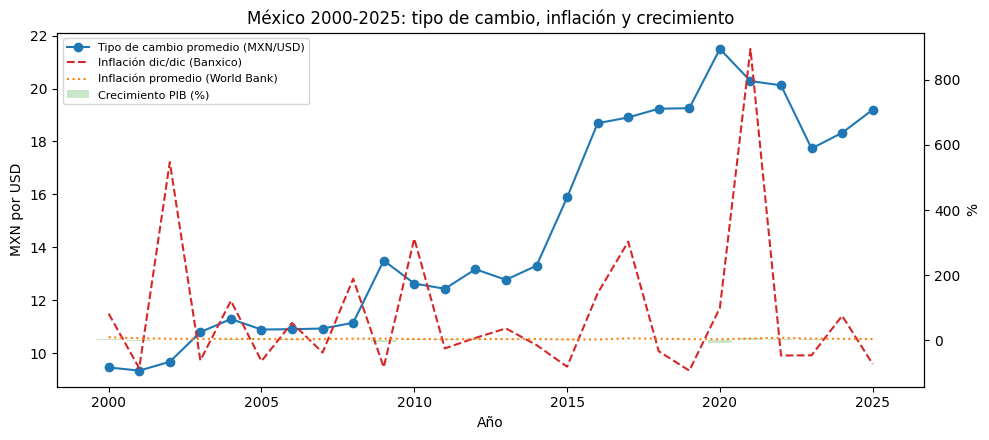

In [ ]:
fig, ax1 = plt.subplots(figsize=(10, 4.5))
ax1.plot(df_etl["anio"], df_etl["tc_promedio"], color="tab:blue", marker="o", label="Tipo de cambio promedio (MXN/USD)")
ax1.set_ylabel("MXN por USD"); ax1.set_xlabel("Año")
ax2 = ax1.twinx()
ax2.plot(df_etl["anio"], df_etl["inflacion_banxico"], color="tab:red", linestyle="--", label="Inflación dic/dic (Banxico)")
ax2.plot(df_etl["anio"], df_etl["inflacion_wb"], color="tab:orange", linestyle=":", label="Inflación promedio (World Bank)")
ax2.bar(df_etl["anio"], df_etl["pib_crec"], alpha=0.25, color="tab:green", label="Crecimiento PIB (%)")
ax2.set_ylabel("%")
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper left", fontsize=8)
plt.title("México 2000-2025: tipo de cambio, inflación y crecimiento"); plt.tight_layout(); plt.show()

Consulta 4 sobre la tabla del ETL

In [ ]:
sql4 = f"""
SELECT ROUND(CORR(tc_var_pct, inflacion_banxico), 3) AS corr_depreciacion_inflacion,
       ROUND(CORR(tc_var_pct, pib_crec), 3) AS corr_depreciacion_pib,
       ROUND(CORR(inflacion_banxico, pib_crec), 3) AS corr_inflacion_pib,
       COUNT(*) AS anios
FROM `{TBL_ETL}`
"""
q(sql4)

,corr_depreciacion_inflacion,corr_depreciacion_pib,corr_inflacion_pib,anios
0,-0.226,-0.514,0.245,26


Conectar con MONGO

In [1]:
!pip install -q pymongo
from pymongo import MongoClient
from google.colab import userdata

# La cadena de conexión vive en Secretos, no en el código
MONGO_URI = userdata.get('MONGO_URI')

client = MongoClient(MONGO_URI, serverSelectionTimeoutMS=10000)
client.admin.command('ping')   # si falla, lanza un error
print('Conexión exitosa a MongoDB Atlas')

db = client['banxico_db']
coleccion = db['tipo_cambio_fix']

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 22.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 354.8/354.8 kB 27.4 MB/s eta 0:00:00
Conexión exitosa a MongoDB Atlas


Cargar registros como documentos

In [3]:
import pandas as pd
from google.colab import drive

drive.mount('/content/drive')

RUTA_CSV = '/content/drive/MyDrive/datasets/procesados/tipo_cambio_fix_2020_2025.csv'

df = pd.read_csv(RUTA_CSV, parse_dates=['fecha'])
print(f'Registros leídos del CSV: {len(df)}')

documentos = df.to_dict(orient='records')
print('Ejemplo de documento:', documentos[0])

coleccion.delete_many({})

resultado = coleccion.insert_many(documentos)
print(f'Documentos insertados: {len(resultado.inserted_ids)}')

print(f'Documentos en la colección: {coleccion.count_documents({})}')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Registros leídos del CSV: 1510
Ejemplo de documento: {'fecha': Timestamp('2020-01-02 00:00:00'), 'tipo_cambio': 18.8817}
Documentos insertados: 1510
Documentos en la colección: 1510


In [5]:
from datetime import datetime

# --- Consulta 1: filtro por valor (dólar muy caro) ---
# Días en que el tipo de cambio superó los 24 pesos, del más caro al más barato
c1 = list(coleccion.find({'tipo_cambio': {'$gt': 24}}, {'_id': 0})
                   .sort('tipo_cambio', -1))
print(f'Consulta 1: {len(c1)} días con tipo de cambio > 24')
for d in c1[:5]:
    print(d)

# --- Consulta 2: filtro por rango de fechas (un mes específico) ---
# Junio de 2024, en orden cronológico
c2 = list(coleccion.find({'fecha': {'$gte': datetime(2024, 6, 1),
                                    '$lte': datetime(2024, 6, 30)}}, {'_id': 0})
                   .sort('fecha', 1))
print(f'\nConsulta 2: {len(c2)} registros en junio de 2024')
print('Primero:', c2[0])
print('Último:', c2[-1])

# --- Consulta 3: filtro + agregación (promedio, mínimo y máximo por año) ---
pipeline = [
    {'$match': {'fecha': {'$gte': datetime(2022, 1, 1)}}},       # solo 2022 en adelante
    {'$group': {'_id': {'$year': '$fecha'},
                'promedio': {'$avg': '$tipo_cambio'},
                'minimo': {'$min': '$tipo_cambio'},
                'maximo': {'$max': '$tipo_cambio'},
                'n_dias': {'$sum': 1}}},
    {'$sort': {'_id': 1}}
]
print('\nConsulta 3: estadísticas por año (2022 en adelante)')
for fila in coleccion.aggregate(pipeline):
    print(f"{fila['_id']}: prom={fila['promedio']:.4f} | "
          f"min={fila['minimo']:.4f} | max={fila['maximo']:.4f} | días={fila['n_dias']}")

print('Rango de fechas de los 28 días:', min(d['fecha'] for d in c1), 'a', max(d['fecha'] for d in c1))

Consulta 1: 28 días con tipo de cambio > 24
{'fecha': datetime.datetime(2020, 3, 24, 0, 0), 'tipo_cambio': 25.1185}
{'fecha': datetime.datetime(2020, 3, 23, 0, 0), 'tipo_cambio': 25.0782}
{'fecha': datetime.datetime(2020, 4, 24, 0, 0), 'tipo_cambio': 24.8583}
{'fecha': datetime.datetime(2020, 4, 27, 0, 0), 'tipo_cambio': 24.8492}
{'fecha': datetime.datetime(2020, 4, 3, 0, 0), 'tipo_cambio': 24.6938}

Consulta 2: 20 registros en junio de 2024
Primero: {'fecha': datetime.datetime(2024, 6, 3, 0, 0), 'tipo_cambio': 17.6338}
Último: {'fecha': datetime.datetime(2024, 6, 28, 0, 0), 'tipo_cambio': 18.2478}

Consulta 3: estadísticas por año (2022 en adelante)
2022: prom=20.1205 | min=19.1433 | max=21.3775 | días=252
2023: prom=17.7338 | min=16.6895 | max=19.4883 | días=251
2024: prom=18.3263 | min=16.3357 | max=20.7862 | días=251
2025: prom=19.1996 | min=17.9042 | max=20.8518 | días=251
Rango de fechas de los 28 días: 2020-03-19 00:00:00 a 2020-05-14 00:00:00


Conectar con Keaggle

In [7]:
import os
from google.colab import userdata

os.environ['KAGGLE_API_TOKEN'] = userdata.get('KAGGLE_API_TOKEN')

!pip install -q --upgrade kaggle

!kaggle datasets list -s "mexico exchange rate" | head -n 6

ref                                                           title                                                  size  lastUpdated                 downloadCount  voteCount  usabilityRating  
------------------------------------------------------------  -----------------------------------------------  ----------  --------------------------  -------------  ---------  ---------------  
lucafrance/the-world-factbook-by-cia                          The World Factbook by CIA                           4940588  2025-03-14 19:36:06.400000           8960        192  0.9411765        
federalreserve/mexico--u.s.-foreign-exchange-rate             Mexico / U.S. Foreign Exchange Rate                   38103  2019-12-24 01:28:32.607000             55          1  0.64705884       
frtgnn/daily-macrofinancial-pulse-of-emerging-markets         Daily Macro‑Financial Pulse of Emerging Markets      116641  2025-07-28 09:02:29.197000            108          5  1                
allratestoday/central-ban